Add you import statements and the database connection statements in the below code block

Database file path: /course/data/CSE-578/dinofunworld.db

In [3]:
# import statements here
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform  
%matplotlib inline

db_filename = '/course/data/CSE-578/dinofunworld.db'
conn = sqlite3.connect(db_filename) 
c = conn.cursor()

**Question 1:**

Create and display a dendrogram of the trajectories of the 5 visitors specified above. The clustering algorithm used to create the dendrogram should use the average distance between points in a cluster.

**NOTE:**

* You can reuse the distance matrix from Assignment 3.
* Make sure to use the correct clustering algorithm.
* The dendrogram  should have the following parameters:
    * Title should be '**Dendrogram of Trajectories of 5 Visitors to the Park**'
    * xlabel should be '**Visitor ID**' and ylabel should be '**Distance**'.
* The plot must not have the following parameters,
    * do not set figure size
    * do not set font size or font-weight for titles and labels




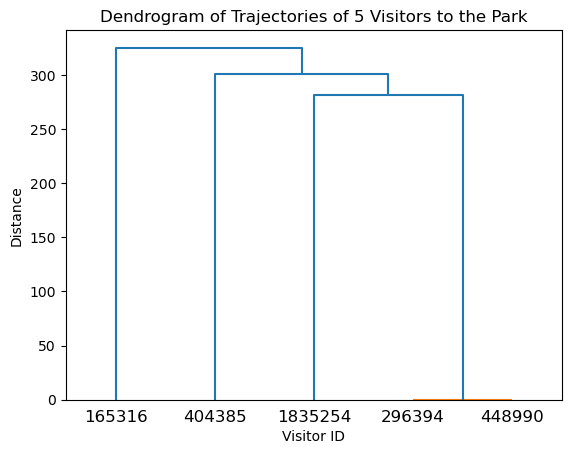

In [4]:
### TEST FUNCTION: test_question1
# DO NOT MODIFY OR REMOVE THE ABOVE LINE
# your code here
sql_query = """ 
SELECT visitorID, sequence
FROM sequences 
WHERE visitorID IN (165316, 1835254, 296394, 404385, 448990);
"""
c.execute(sql_query)
vistors_sequence_data = c.fetchall()
vistors_sequence_data_df = pd.DataFrame.from_records(vistors_sequence_data, columns=['VisitorID', 'Sequence'])
vistors_sequence_data_df['Sequence'] = vistors_sequence_data_df["Sequence"].apply(lambda seq: [int(i) for i in seq.split("-")])
visitor_ids = list(vistors_sequence_data_df['VisitorID'])
distance_matrix = {}
for i, r1 in vistors_sequence_data_df.iterrows():
    v1 = r1['VisitorID']
    s1 = r1['Sequence']
    distance_matrix[v1] = {}
    for j, r2 in vistors_sequence_data_df.iterrows():
        v2 = r2['VisitorID']
        s2 = r2['Sequence']
        if v1 != v2:  
            distance_matrix[v1][v2] = sum(1 for x, y in zip(s1, s2) if x != y)
        else:
            distance_matrix[v1][v2] = 0
X = np.array([[distance_matrix[v1][v2] for v2 in visitor_ids] for v1 in visitor_ids])
X = squareform(X)
links = linkage(X, method='average')
dendrogram(links, labels=visitor_ids)
plt.title("Dendrogram of Trajectories of 5 Visitors to the Park")
plt.xlabel("Visitor ID")
plt.ylabel("Distance")
plt.show()